# <font color = "tomato">ATHENA–CAMM Hackathon | Ternary Spectroscopy
-  Two challenges, one hidden measurement API</font>

**Challenge 1**
    
    Learn to measure a spectrum:** At one fixed composition, choose wavelengths and acquisition durations to reconstruct the complete **512-channel spectrum**.

**Challenge 2**
    
    Explore the whole ternary wafer:** Choose both compositions and wavelengths/time to reconstruct the full **spectral cube** $S(x,y,E)$ across the ternary triangle.

**Scientific objective:** 

    Minimize reconstruction error compared with organizer-only hidden noiseless ground truth. **Phase classification is not the scoring target.** The true phase diagram, true spectra, and noise laws are not visible to participants.

The following baselines are intentionally simple. Replace their acquisition and interpolation strategies with your own. Running the acquisition cells consumes episode budget.

<a href="https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_23_10302026/ATHENA_Ternary_Spectroscopy.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## 0. Connect to the common HTTPS API

Use the actual URL from the organizers. The API must have the **two-challenge backend** deployed; the original single-task API will not work for Challenge 2.

In [1]:
import requests
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from matplotlib.tri import Triangulation

BASE_URL = "https://athena-spectral-api.onrender.com"  # Replace if organizer provides a different URL
BASE_URL = BASE_URL.rstrip("/")

def api(method, path, payload=None, token=None):
    headers = {"X-Session-ID": token} if token else {}
    response = requests.request(method, BASE_URL + path, json=payload, headers=headers, timeout=120)
    if not response.ok:
        raise RuntimeError(f"{method} {path}: HTTP {response.status_code}: {response.text[:500]}")
    return response.json()

info = api("GET", "/info")
print("Available tasks:", info["tasks"])
print("Single-spectrum budget:", info["time_budget"])
print("Full-wafer budget:", info["cube_time_budget"])
print("Evaluation cube shape:", info["cube_shape"])
energy = np.linspace(*info["wavelength_range"], info["channels"])


Available tasks: ['single-spectrum', 'ternary-spectral-cube']
Single-spectrum budget: 30.0
Full-wafer budget: 900.0
Evaluation cube shape: [120, 512]


# <font color = "plum">**Challenge 1**</font>
    
    Learn to measure a spectrum

## 1. Start an experimental session

In [2]:
episode1 = api(
    "POST",
    "/session",
    {"task": "single-spectrum"}
)

TOKEN1 = episode1["session_id"]

x = info["composition"]["x"]
y = info["composition"]["y"]

print(f"Composition: A={x:.2f}, B={y:.2f}, C={1-x-y:.2f}")
print("Time budget:", episode1["time_budget"])
print("Spectral channels:", len(energy))

Composition: A=0.30, B=0.40, C=0.30
Time budget: 30.0
Spectral channels: 512


## 2. Define measurement functions

In [3]:
def measure1(wavelength, time):
    return api(
        "POST",
        "/pixel",
        {
            "wavelength": float(wavelength),
            "time": float(time)
        },
        TOKEN1
    )

def budget1():
    return api("GET", "/budget", token=TOKEN1)

print(budget1())

{'time_used': 0.0, 'time_remaining': 30.0, 'measurements': 0}


## 3. Baseline: Measure 30 wavelengths

In [4]:
n1 = 30

sample_E1 = np.linspace(
    energy.min(),
    energy.max(),
    n1
)

t1 = episode1["time_budget"] / n1

observations1 = []

for wavelength in sample_E1:
    result = measure1(wavelength, t1)
    observations1.append(result)

measured_E1 = np.array([
    r["wavelength"] for r in observations1
])

measured_I1 = np.array([
    r["intensity"] for r in observations1
])

print("Measurements completed:", len(observations1))
print("Remaining budget:", budget1())

Measurements completed: 30
Remaining budget: {'time_used': 30.0, 'time_remaining': 0.0, 'measurements': 30}


## 4. Reconstruct the complete spectrum

In [5]:
predicted_spectrum1 = np.interp(
    energy,
    measured_E1,
    measured_I1
)

print("Reconstructed channels:", len(predicted_spectrum1))

Reconstructed channels: 512


## 5. Plot the prediction

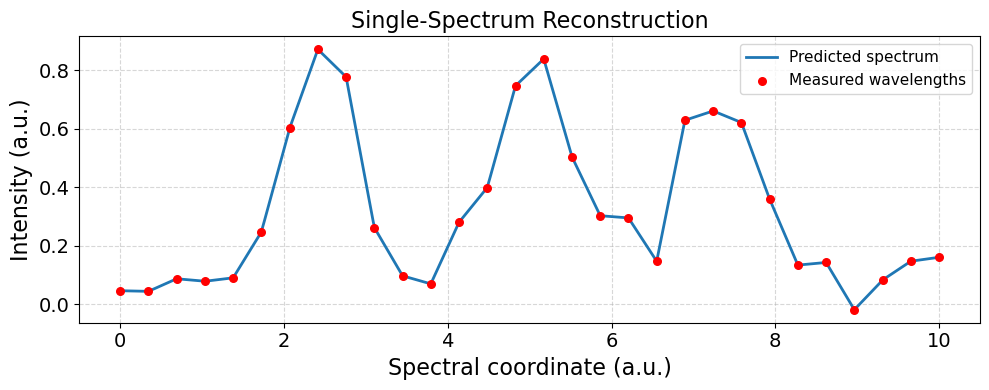

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    energy,
    predicted_spectrum1,
    lw=2,
    label="Predicted spectrum"
)

ax.scatter(
    measured_E1,
    measured_I1,
    color="red",
    s=30,
    label="Measured wavelengths",
    zorder=3
)

ax.set(
    xlabel="Spectral coordinate (a.u.)",
    ylabel="Intensity (a.u.)",
    title="Single-Spectrum Reconstruction"
)

ax.set_title("Single-Spectrum Reconstruction", fontsize=16)
ax.set_xlabel("Spectral coordinate (a.u.)", fontsize=16)
ax.set_ylabel("Intensity (a.u.)", fontsize=16)

# Make tick labels larger
ax.tick_params(axis="both", labelsize=14)

ax.legend(fontsize=11, loc = "upper right")
plt.grid(alpha=0.5, linestyle="--")
plt.tight_layout()
plt.show()

##  6. Submit the prediction

In [7]:
submission1 = {
    "energy": energy.tolist(),
    "predicted_intensity": predicted_spectrum1.tolist()
}

# Run only when ready to finalize your prediction
# result1 = api("POST", "/submit", submission1, TOKEN1)
# print(result1)

---
# <font color ="red">**Challenge 2**</font>

— Optimal exploration of the full ternary spectral landscape

**Goal:** Reconstruct $S(x,y,E)$ for every composition on an organizer-defined triangular evaluation grid and every one of 512 spectral channels. The agent chooses **where** to measure, **which wavelengths** to measure there, and **how long** to acquire each observation.

The initial budget is **900 time units** (30× the single-spectrum budget), pending organizer calibration. The returned grid is an **evaluation grid**, not a measurement grid requirement. Measurements may be requested at any valid composition $x\ge0$, $y\ge0$, $x+y\le1$.

The baseline below samples 24 compositions and 12 wavelengths per composition (288 scalar measurements). It reconstructs spectra by 1D interpolation, followed by 2D interpolation over composition. This is only a starting point; it can miss narrow peaks and sharp phase boundaries.

In [8]:
episode2 = api("POST", "/session", {"challenge": 2})
TOKEN2 = episode2["session_id"]

# Evaluation compositions
coords_eval = np.array(info["cube_grid"])

# Measurement function
def measure2(x, y, wavelength, time):
    return api(
        "POST",
        "/pixel",
        {
            "x": float(x),
            "y": float(y),
            "wavelength": float(wavelength),
            "time": float(time)
        },
        TOKEN2
    )

# Check remaining budget
def budget2():
    return api("GET", "/budget", token=TOKEN2)

print("Evaluation locations:", len(coords_eval))
print("Time budget:", episode2["time_budget"])

Evaluation locations: 120
Time budget: 900.0


## 1. baseline 

* Sparse ternary locations and sparse spectra

A triangular **six-level** measurement grid has 21 unique compositions. We add three interior points for **24 compositions total**, with 12 wavelengths per composition. All observations share the budget equally.

**Warning:** This cell makes **288 API calls** and consumes the episode's entire measurement budget. It may take some time on a remote server. For a quick connectivity test, measure one point in a fresh test episode instead of running the baseline.

In [9]:
# 1. Choose where to measure
n_points = 6

locations = np.array([
    (i / (n_points - 1), j / (n_points - 1))
    for i in range(n_points)
    for j in range(n_points - i)
])

# 2. Choose which wavelengths to measure
n_wavelengths = 12

wavelengths = np.linspace(
    energy.min(),
    energy.max(),
    n_wavelengths
)

# 3. Divide the time budget equally
time_per_measurement = episode2["time_budget"] / (
    len(locations) * n_wavelengths
)

# 4. Collect measurements
measurements = np.zeros((len(locations), n_wavelengths))

for i, (x, y) in enumerate(locations):
    for j, wavelength in enumerate(wavelengths):
        measurements[i, j] = measure2(
            x, y, wavelength, time_per_measurement
        )["intensity"]

print("Locations:", len(locations))
print("Wavelengths per location:", n_wavelengths)
print("Total measurements:", measurements.size)
print("Remaining budget:", budget2())

Locations: 21
Wavelengths per location: 12
Total measurements: 252
Remaining budget: {'time_used': 899.9999999999975, 'time_remaining': 2.5011104298755527e-12, 'measurements': 252}


## 2. Reconstruct the complete cube

**Stage A:** Interpolate each measured 12-channel spectrum to all 512 channels.

**Stage B:** At each channel, interpolate those estimates spatially onto the prescribed triangular evaluation grid. Use nearest-neighbor estimates where linear interpolation is undefined. Output shape is `(N_compositions, 512)`; rows must follow the order of `info["cube_grid"]`.

In [10]:
# 1. Reconstruct 512-channel spectra at measured locations
measured_spectra = np.array([
    np.interp(energy, wavelengths, spectrum)
    for spectrum in measurements
])

# 2. Predict spectra at all evaluation compositions
predicted_cube = griddata(
    locations,
    measured_spectra,
    coords_eval,
    method="linear"
)

# 3. Fill any locations outside the interpolation region
nearest_cube = griddata(
    locations,
    measured_spectra,
    coords_eval,
    method="nearest"
)

predicted_cube = np.where(
    np.isnan(predicted_cube),
    nearest_cube,
    predicted_cube
)

print("Predicted spectral cube:", predicted_cube.shape)

Predicted spectral cube: (120, 512)


## 3. Visualize what you actually predict

The ternary plots below show **predicted spectral intensity at three energies**, not the hidden phase labels. Black circles show sampled compositions.

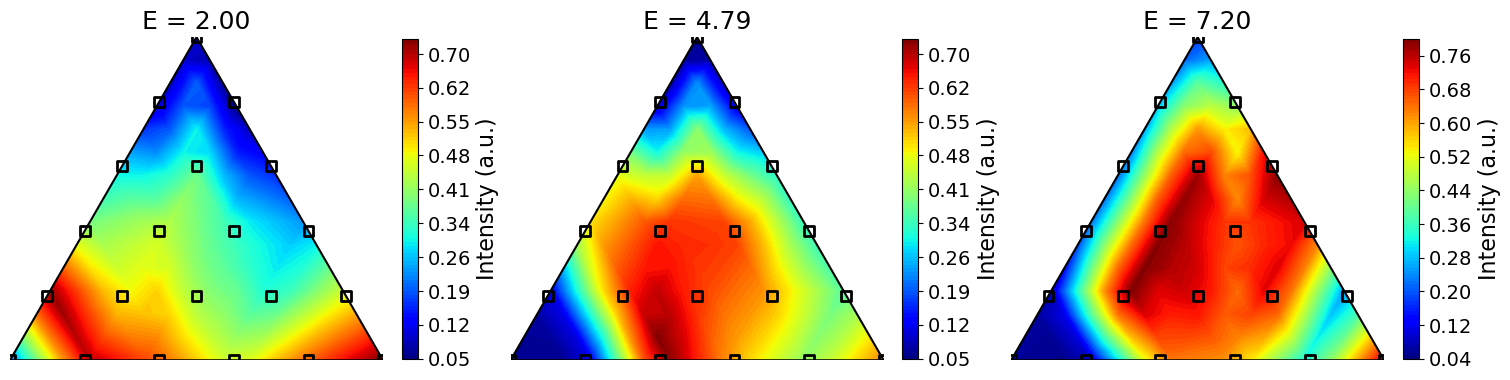

In [11]:
def to_triangle(xy):
    x, y = xy[:, 0], xy[:, 1]
    z = 1 - x - y
    return y + 0.5*z, np.sqrt(3)/2*z

X, Y = to_triangle(coords_eval)
Xm, Ym = to_triangle(locations)
tri = Triangulation(X, Y)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)

for ax, E0 in zip(axes, [2.0, 4.8, 7.2]):
    idx = np.argmin(abs(energy - E0))

    im = ax.tricontourf(tri, predicted_cube[:, idx], levels=100, cmap="jet")
    ax.scatter(Xm, Ym, marker="s",s=50, facecolors="none", edgecolors="black", linewidths=2)
    ax.plot([0, 1, .5, 0], [0, 0, np.sqrt(3)/2, 0], "k-", lw=1.5)

    ax.set_title(f"E = {energy[idx]:.2f}", fontsize=18)
    ax.set_aspect("equal")
    ax.axis("off")

    cbar = fig.colorbar(im, ax=ax, shrink=0.65, format="%.2f")
    cbar.set_label("Intensity (a.u.)", fontsize=16)
    cbar.ax.tick_params(labelsize=14)

plt.show()

This plot compares reconstructed spectra at three selected evaluation compositions. These are the required scientific outputs for Challenge 2. A phase map is optional and would require an additional phase-inference model.

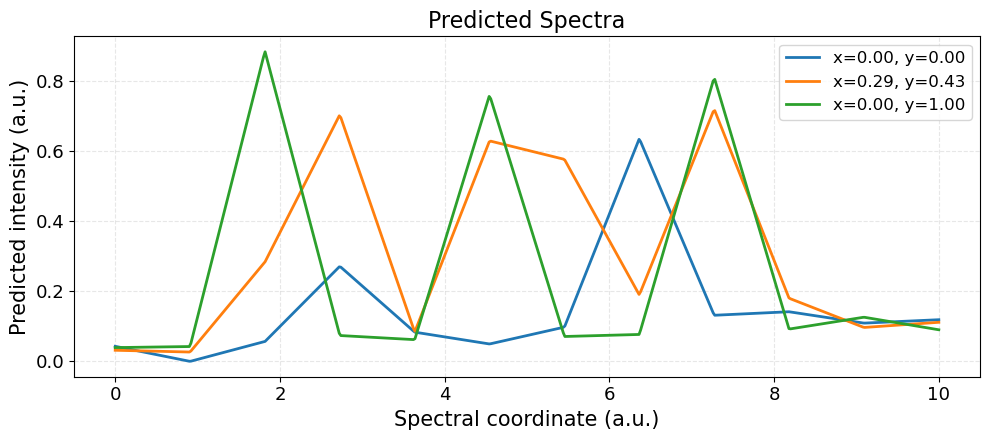

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))

for x, y in [(0, 0), (0.3, 0.4), (0, 1)]:
    i = np.argmin(np.sum((coords_eval - [x, y])**2, axis=1))
    ax.plot(energy, predicted_cube[i], lw=2,
            label=f"x={coords_eval[i,0]:.2f}, y={coords_eval[i,1]:.2f}")

ax.set_xlabel("Spectral coordinate (a.u.)", fontsize=15)
ax.set_ylabel("Predicted intensity (a.u.)", fontsize=15)
ax.set_title("Predicted Spectra", fontsize=16)
ax.tick_params(labelsize=13)
ax.legend(fontsize=12)
ax.grid(alpha=0.3, linestyle="--")

plt.tight_layout()
plt.show()

## 4. Challenge 2 submission

The organizer checks the predicted entire spectral cube against the clean hidden cube on the **fixed evaluation grid**. It returns RMSE and resource usage in this prototype. Submitting locks the episode. **Uncomment to submit.**

In [13]:
submission2 = {"predictions": predicted_cube.tolist()}
# score2 = api("POST", "/submit-cube", submission2, TOKEN2)
# print("Challenge 2 score:",score2)


## <font color = "blue">**Competition Guidelines**</font>

- Objective: Reconstruct the hidden spectra as accurately as possible using limited experimental time.

- Measurements: Both challenges use the same API. Participants choose measurement wavelengths and acquisition times. Challenge 2 also allows selecting compositions (x, y).

- Time budget: Every measurement consumes part of the available budget.

- Challenge 1: Reconstruct a complete 512-channel spectrum at one fixed composition.

- Challenge 2: Reconstruct the full spectral landscape across the ternary composition space.

- Evaluation: Predictions are compared with hidden ground truth using root mean squared error (RMSE). Lower RMSE is better.

- Methods: Participants are encouraged to explore adaptive sampling, machine learning, Bayesian optimization, or other reconstruction approaches.

* **Important Notes**

The spectral coordinate is expressed in arbitrary units (a.u.). The true spectra, phase diagram, and noise model remain hidden.

The provided examples are simple baselines, not optimal solutions. Participants should develop their own strategies to improve reconstruction accuracy.